# Held-out performance and calibration

**Purpose:** Evaluate frozen classifiers, independently fit calibration, examine patient-bootstrap uncertainty and score example encounters.

Requires the complete project folder and dependencies from `requirements.txt`; see README.md for local/Colab/Kaggle setup. Matching saved artifacts are reused. Use `force=True` in the phase cell to recompute. Outputs must remain visible when saving.

In [1]:
from pathlib import Path
import os, sys
for name in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ.setdefault(name, '2')
candidates = [Path.cwd(), *Path.cwd().parents,
              Path('/content/hospital-readmission'), Path('/kaggle/working/hospital-readmission')]
ROOT = next((p for p in candidates if (p / 'config.json').exists() and (p / 'readmission').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Extract the full project and set the working directory to hospital-readmission first. See README.md.')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image, JSON
from readmission.common import read_json
from readmission.pipeline import run_phase
pd.set_option('display.max_columns', 30)
print('Project:', ROOT.name)


Project: hospital-readmission


In [2]:
run_phase('evaluation')

Phase data: reusing verified matching artifacts.


Phase data: reusing verified matching artifacts.


Phase models: reusing verified matching artifacts.


Phase evaluation: reusing verified matching artifacts.


In [3]:
display(pd.read_csv(ROOT / 'artifacts/tables/test_metrics.csv'))

,experiment,stage,calibration,accuracy,precision,recall,f1,roc_auc,average_precision,brier_score,log_loss,tn,fp,fn,tp,threshold,training_seconds,predict_seconds,calibration_seconds
0,logistic_regression__all,baseline,none,0.885081,0.506173,0.017896,0.034570,0.664701,0.222150,0.097356,0.337981,17596,40,2250,41,0.5,5.489186,0.477066,0.000000
1,logistic_regression__all,tuned,none,0.885081,0.506173,0.017896,0.034570,0.664701,0.222150,0.097356,0.337981,17596,40,2250,41,0.5,5.034353,0.518720,0.000000
2,logistic_regression__all,tuned,sigmoid,0.885281,0.533333,0.017460,0.033812,0.664701,0.222150,0.097338,0.337982,17601,35,2251,40,0.5,5.034353,0.471088,0.775793
3,logistic_regression__mi20,baseline,none,0.885131,0.511905,0.018769,0.036211,0.664259,0.221404,0.097394,0.338118,17595,41,2248,43,0.5,3.461539,0.472261,0.000000
4,logistic_regression__mi20,tuned,none,0.885131,0.511905,0.018769,0.036211,0.664259,0.221404,0.097394,0.338118,17595,41,2248,43,0.5,3.283494,0.774367,0.000000
5,logistic_regression__mi20,tuned,sigmoid,0.885331,0.540541,0.017460,0.033827,0.664259,0.221404,0.097384,0.338131,17602,34,2251,40,0.5,3.283494,0.411985,0.683515
6,random_forest__all,baseline,none,0.885030,0.000000,0.000000,0.000000,0.674593,0.230113,0.097834,0.339462,17636,0,2291,0,0.5,13.622224,0.573194,0.000000
7,random_forest__all,tuned,none,0.885030,0.000000,0.000000,0.000000,0.674593,0.230113,0.097834,0.339462,17636,0,2291,0,0.5,13.912290,0.837468,0.000000
8,random_forest__all,tuned,sigmoid,0.885532,0.575758,0.016587,0.032244,0.674593,0.230113,0.096871,0.336236,17608,28,2253,38,0.5,13.912290,0.492672,1.032765
9,random_forest__mi20,baseline,none,0.885030,0.000000,0.000000,0.000000,0.674303,0.235461,0.097502,0.338325,17636,0,2291,0,0.5,11.207237,0.484439,0.000000


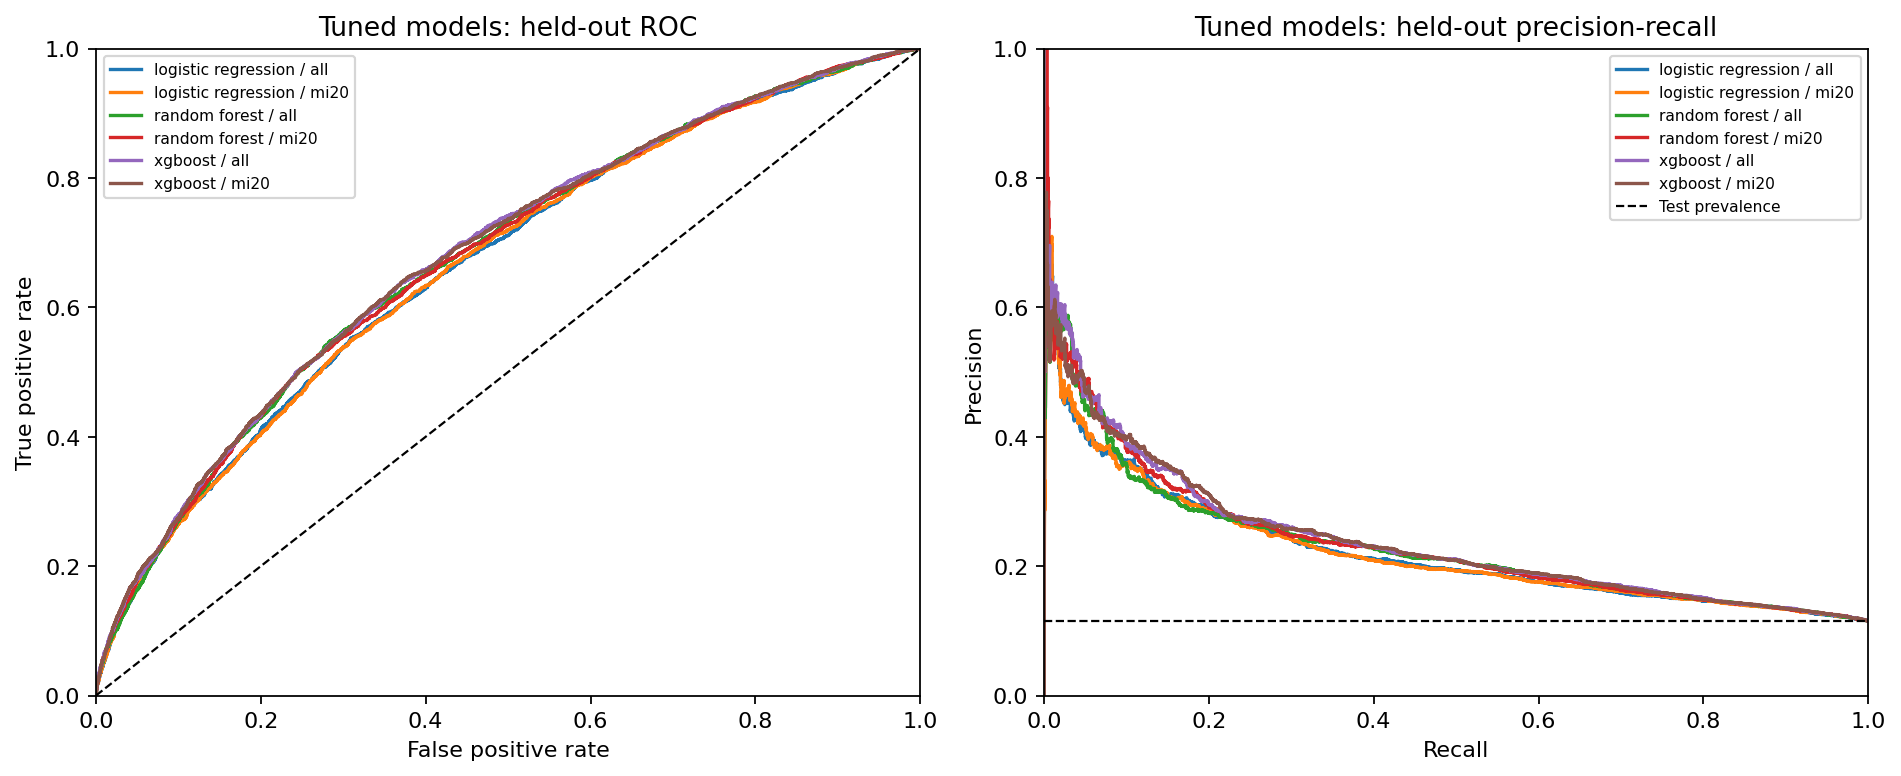

In [4]:
display(Image(filename=str(ROOT / 'artifacts/figures/roc_precision_recall.png'), width=1000))

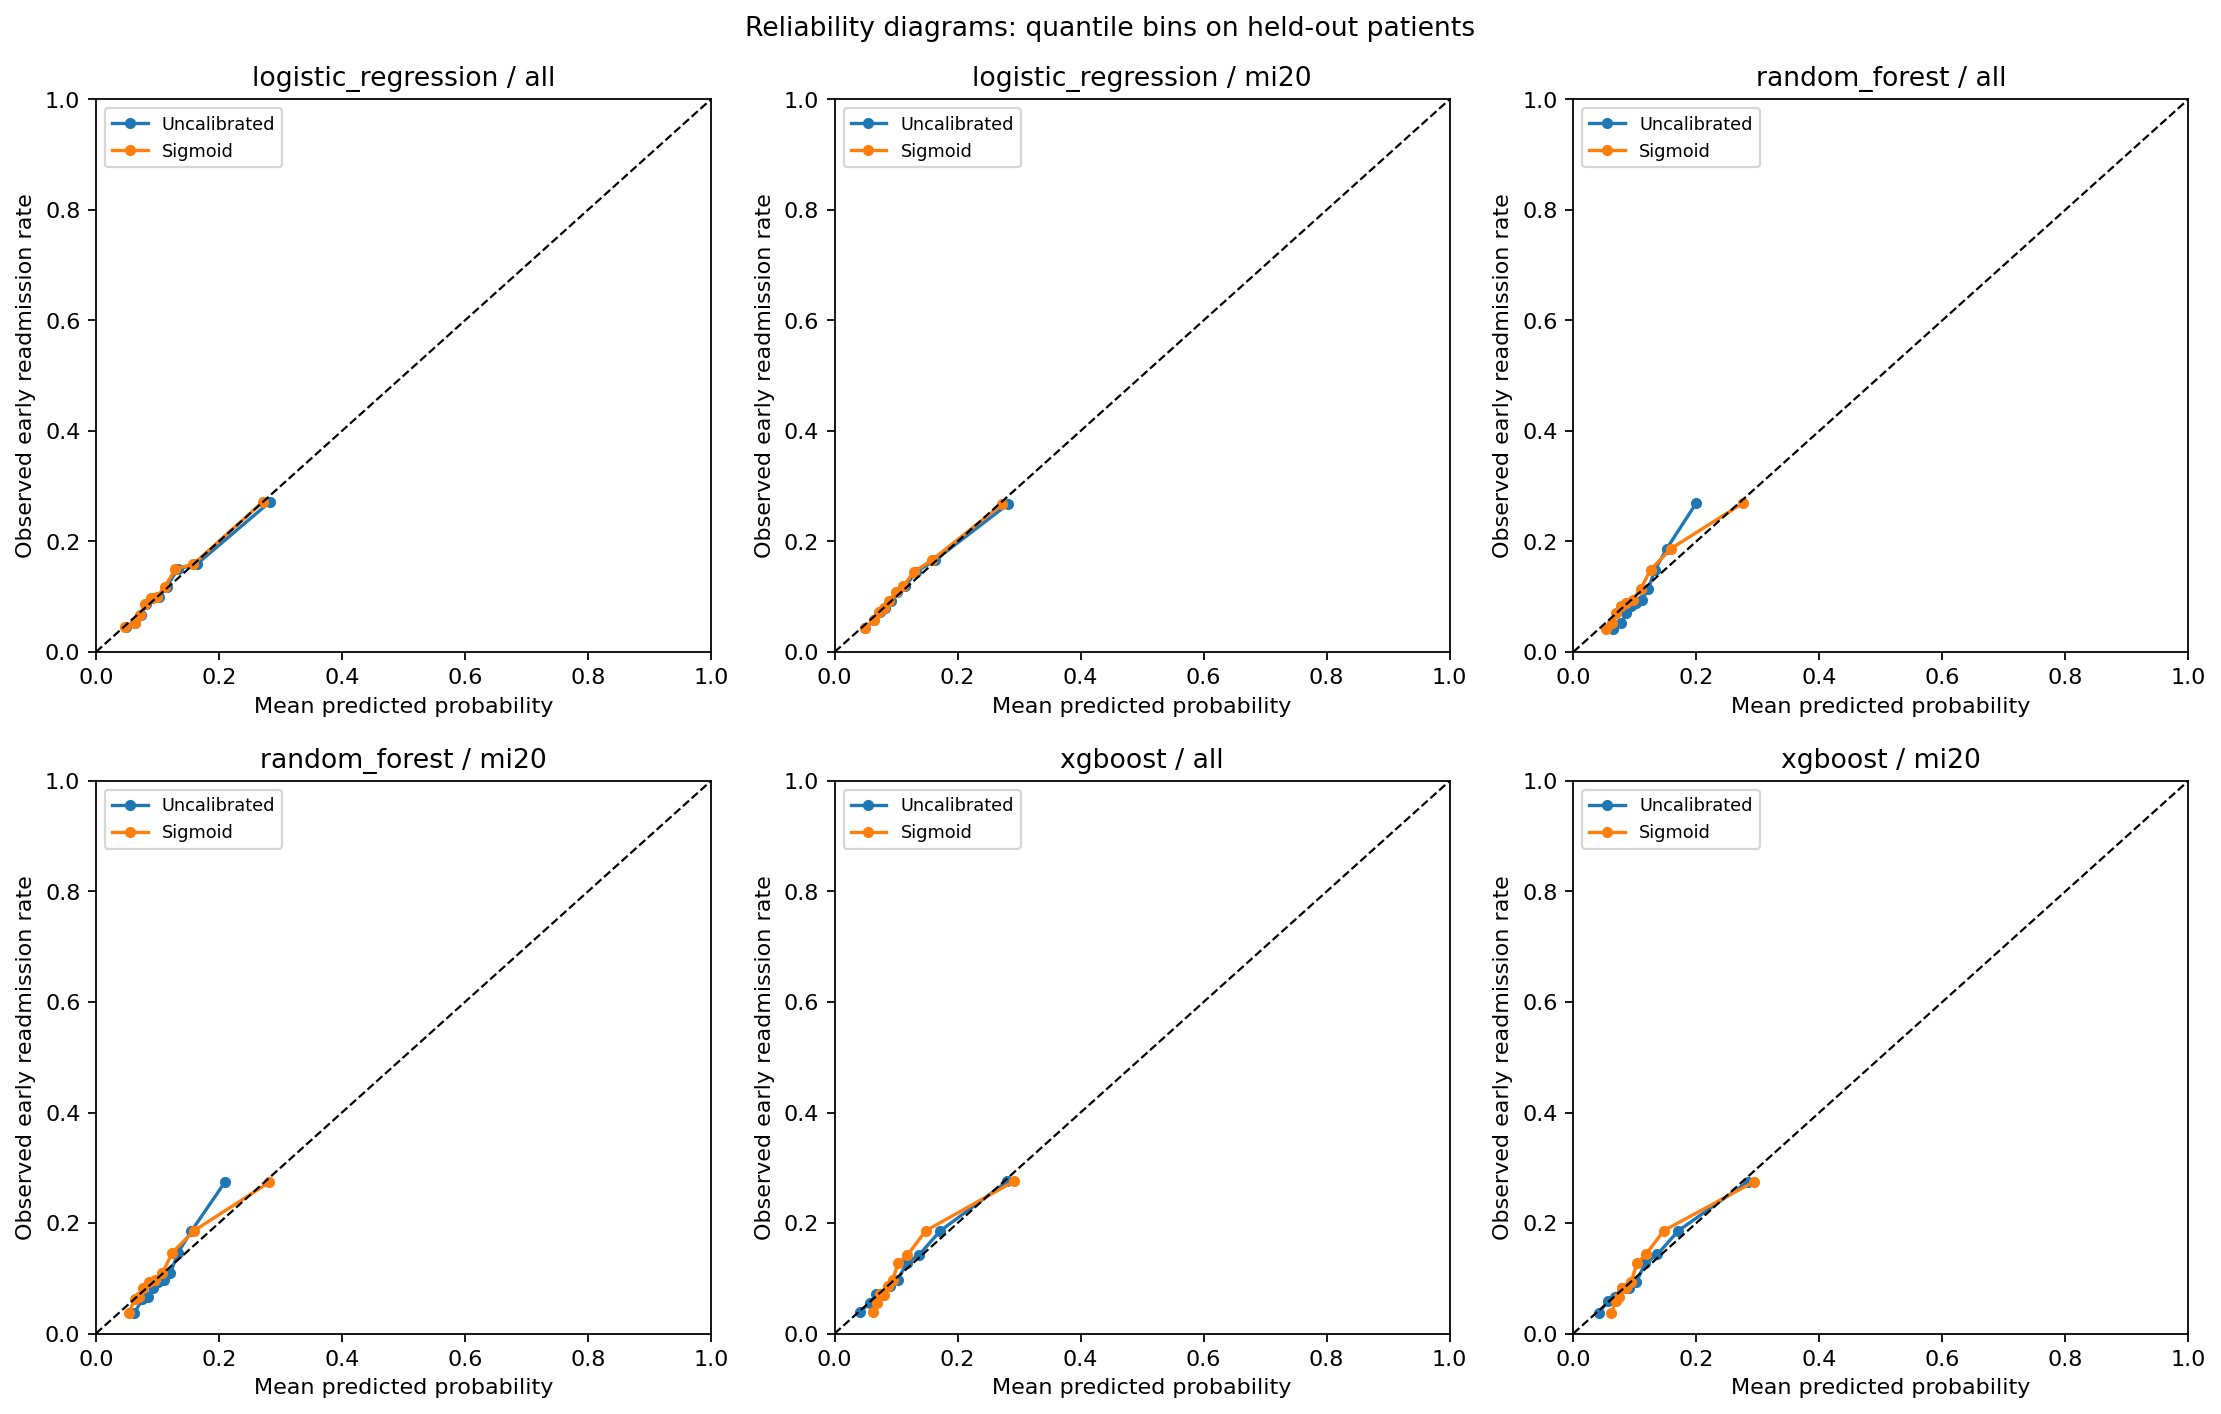

In [5]:
display(Image(filename=str(ROOT / 'artifacts/figures/calibration_comparison.png'), width=1000))

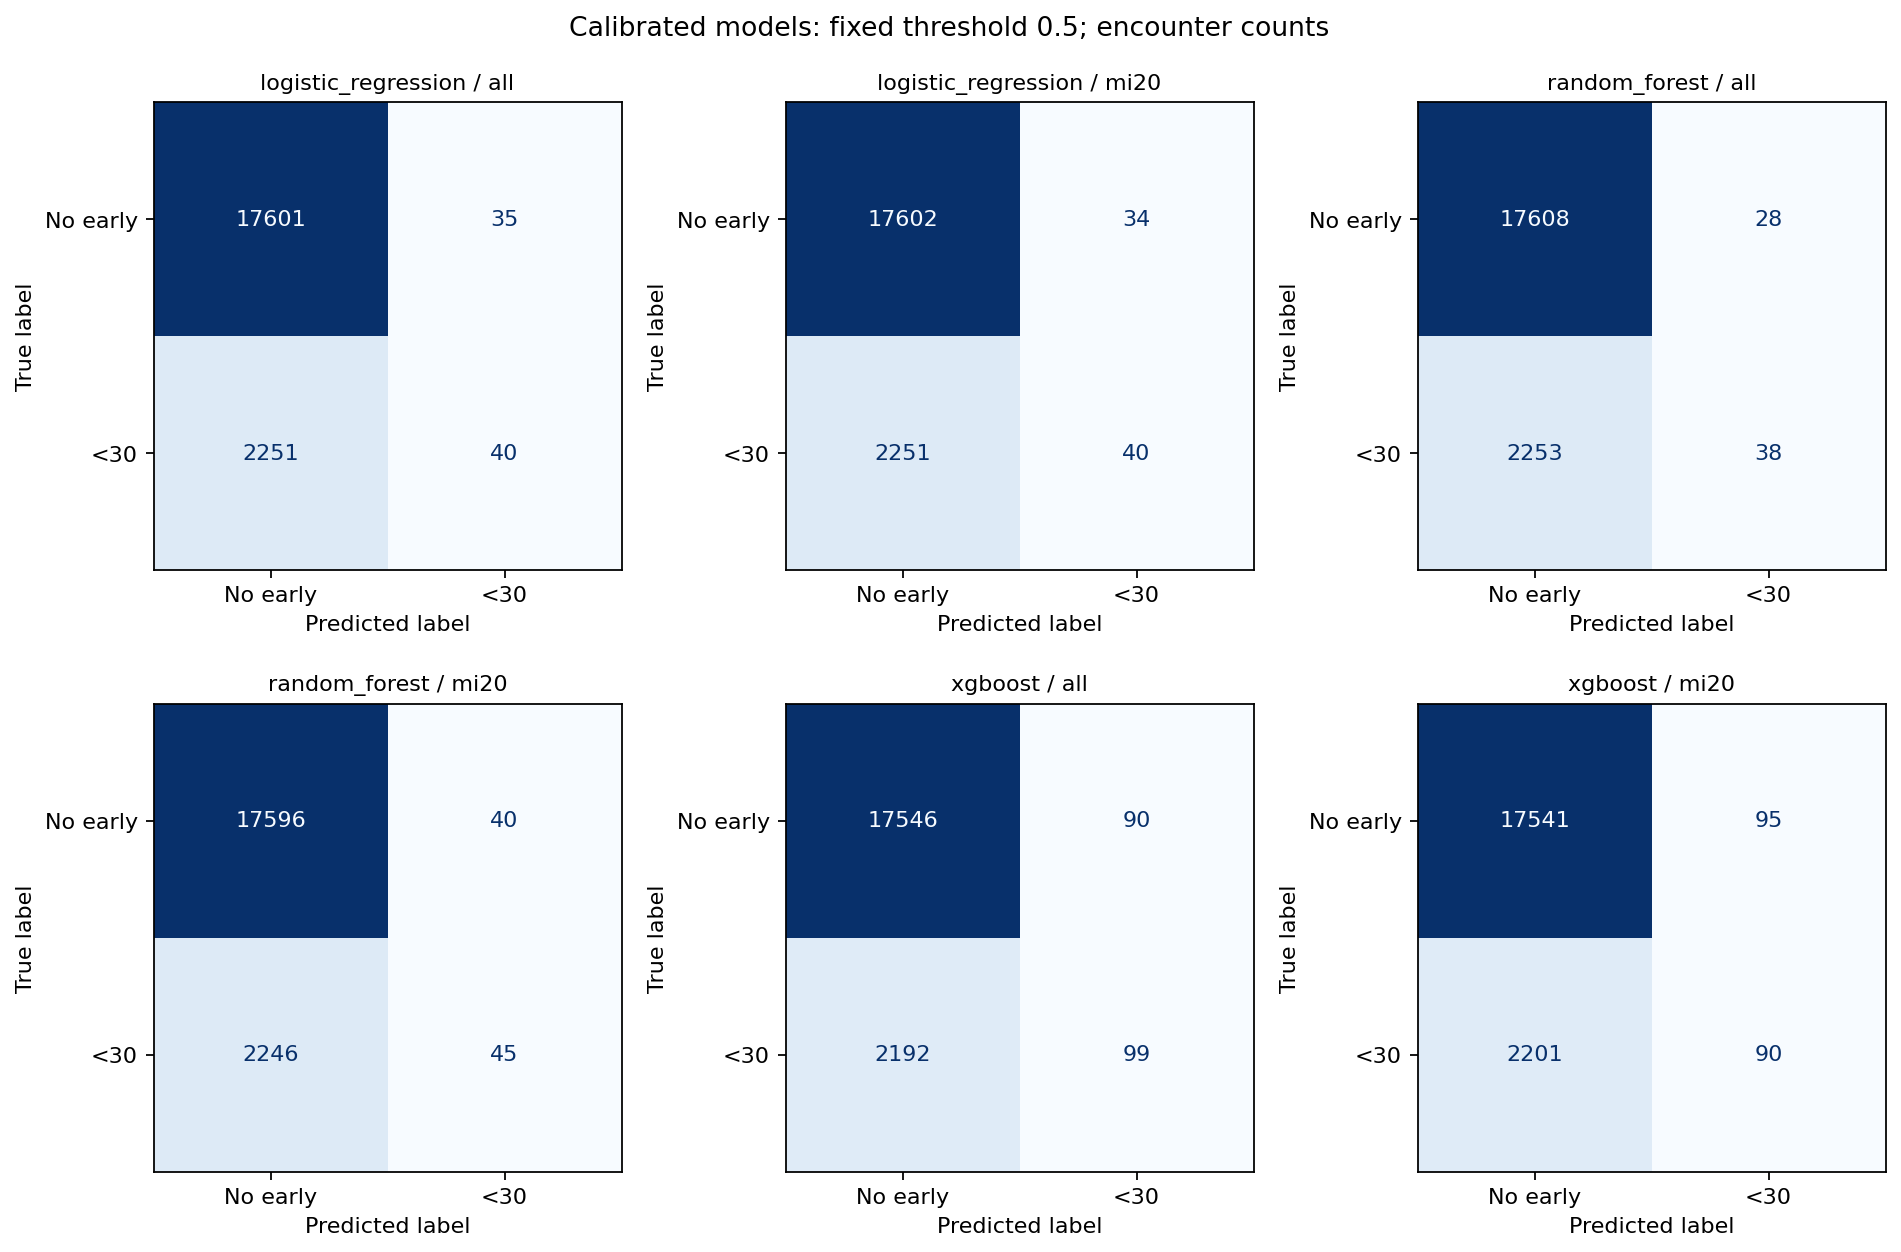

In [6]:
display(Image(filename=str(ROOT / 'artifacts/figures/confusion_matrices.png'), width=1000))

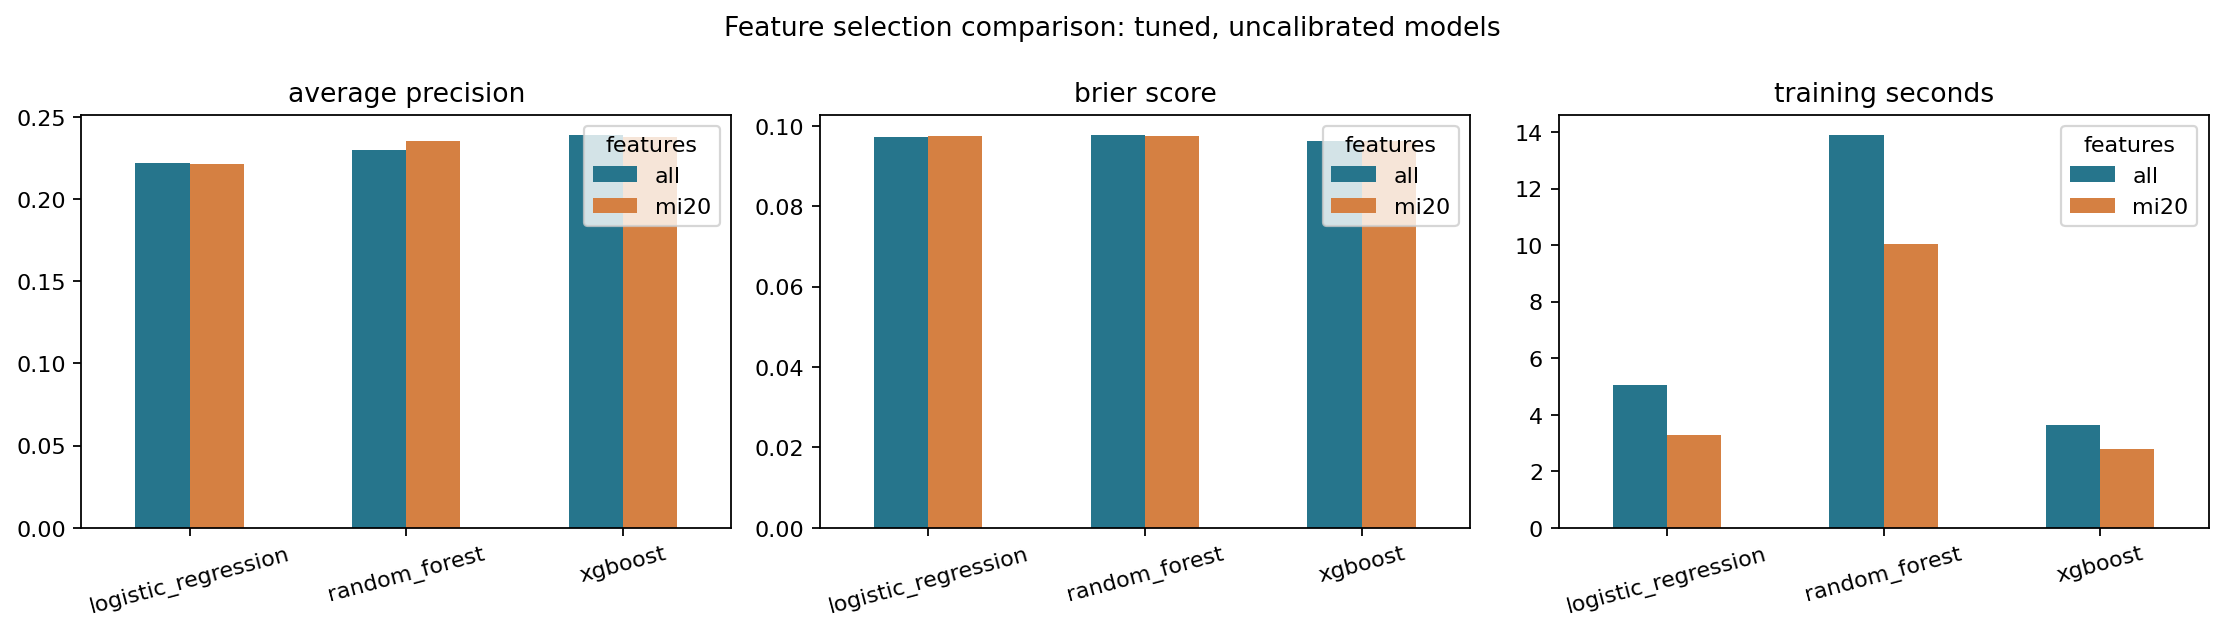

In [7]:
display(Image(filename=str(ROOT / 'artifacts/figures/feature_selection_comparison.png'), width=1000))

In [8]:
display(pd.read_csv(ROOT / 'artifacts/tables/patient_bootstrap_intervals.csv'))

,metric,lower_95,upper_95
0,uncalibrated_roc_auc,0.668763,0.691944
1,uncalibrated_average_precision,0.221153,0.259500
2,uncalibrated_brier_score,0.092618,0.099383
3,calibrated_roc_auc,0.668763,0.691944
4,calibrated_average_precision,0.221153,0.259500
5,calibrated_brier_score,0.092997,0.099831
6,brier_change_calibrated_minus_uncalibrated,0.000193,0.000745


In [9]:
display(pd.read_csv(ROOT / 'artifacts/tables/subgroup_metrics.csv'))

,feature,group,encounters,patients,positive_rate,small_group,accuracy,precision,recall,f1,roc_auc,average_precision,brier_score,log_loss,tn,fp,fn,tp,threshold
0,age,[0-10),33,32,0.000000,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,age,[10-20),128,99,0.039062,False,0.960938,0.000000,0.000000,0.000000,0.700813,0.107354,0.040956,0.175376,123.0,0.0,5.0,0.0,0.5
2,age,[20-30),315,199,0.203175,False,0.847619,0.785714,0.343750,0.478261,0.814181,0.599981,0.123340,0.399411,245.0,6.0,42.0,22.0,0.5
3,age,[30-40),803,568,0.118306,False,0.877958,0.400000,0.063158,0.109091,0.741511,0.278944,0.097566,0.332510,699.0,9.0,89.0,6.0,0.5
4,age,[40-50),1779,1322,0.098370,False,0.901068,0.461538,0.034286,0.063830,0.693990,0.225647,0.084620,0.301263,1597.0,7.0,169.0,6.0,0.5
5,age,[50-60),3332,2476,0.098139,False,0.901861,0.500000,0.039755,0.073654,0.709976,0.243732,0.083102,0.296837,2992.0,13.0,314.0,13.0,0.5
6,age,[60-70),4536,3252,0.114859,False,0.885802,0.545455,0.034549,0.064982,0.658757,0.227523,0.097463,0.339490,4000.0,15.0,503.0,18.0,0.5
7,age,[70-80),5152,3678,0.118983,False,0.880047,0.446809,0.034258,0.063636,0.668592,0.238999,0.099911,0.345046,4513.0,26.0,592.0,21.0,0.5
8,age,[80-90),3351,2319,0.127425,False,0.871979,0.461538,0.028103,0.052980,0.637844,0.207145,0.108744,0.370551,2910.0,14.0,415.0,12.0,0.5
9,age,[90-100),498,380,0.128514,False,0.873494,1.000000,0.015625,0.030769,0.500360,0.156625,0.113044,0.390870,434.0,0.0,63.0,1.0,0.5


In [10]:
display(JSON(read_json('artifacts/evaluation_design.json')))

<IPython.core.display.JSON object>

In [11]:
import subprocess
subprocess.run([sys.executable, 'run.py', 'predict', '--input', 'examples/encounters.csv'], check=True)
display(pd.read_csv(ROOT / 'artifacts/predictions/example_predictions.csv'))

,input_row,recorded_early_readmission_probability,predicted_class,decision_threshold
0,0,0.066187,0,0.5
1,1,0.081418,0,0.5
2,2,0.079131,0,0.5


## Team interpretation prompts

Interpret the low-recall risk of threshold 0.5, whether calibration helped, uncertainty, subgroup limitations, and lack of external validation.

Write your own report discussion after checking the evidence.